# Лабораторная работа №3. Анализ сетевого трафика

## Часть 3. Индивидуальное задание

## Выполнили работу:
### Симахин Степан Андреевич ИНБс-5301-01-00
### Игнатович Вадим Олегович ИНБс-5301-01-00
---
<b> Вариант работы: №26. </b>
Задание по варианту:

```
Вариант 26. Bagging деревьев решений. В блокноте 02 обучите
BaggingClassifier(estimator=DecisionTreeClassifier(random_state=2), n_estimators=20, random_state=2,
n_jobs=-1). Сравните accuracy на внутреннем разбиении и на KDDTest+ с одиночным деревом.
Уменьшился ли разрыв между «внутренней» и честной оценками?
```


## Шаг 0. Подключение датасета

Подключение архива с файлами датасета происходит посредством монтирования файла в Google Drive:

In [4]:
# функция для нормального вывода списков:
def to_str(inp, sep=', '):
  #return str(inp)[1:-1]
  return sep.join(str(it) for it in inp)

# подключение архива datasets.zip, который лежит в Google Диск:
#   прямая ссылка на datasets.zip:
#   https://drive.google.com/file/d/1pt9PgKb9ckkTVfx5YhvzmhfOCREtySsk/view?usp=sharing
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/datasets.zip" -d /content/
print('Файл \'datasets.zip\' подключён')

Mounted at /content/drive
Файл 'datasets.zip' подключён


Подключение файлов в архиве датасета:

In [5]:
import os

# Где лежат данные: рядом с блокнотом (локально) или в /content (Colab)
# DATA_DIR = 'datasets' if os.path.isdir('datasets') else '/content/datasets'
DATA_DIR = 'datasets'

for name in ['ids.csv', 'KDDTrain+.csv', 'KDDTest+.csv']:
    path = os.path.join(DATA_DIR, name)
    assert os.path.isfile(path), (
        f'Файл {name} не найден по пути {path}. '
        'В Colab выполните ячейку «Шаг 0», локально — положите папку datasets рядом с блокнотом.')

print('Успешно найденные файлы датасета: {}.'.format(to_str(sorted(os.listdir(DATA_DIR)))))

Успешно найденные файлы датасета: KDDTest+.csv, KDDTrain+.csv, ids.csv.


Подключение библиотек:

In [13]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)
from matplotlib.colors import LinearSegmentedColormap

print('Библиотеки подключены')

# what is that below?
RANDOM_STATE = 2  # фиксируем, чтобы результаты воспроизводились

Библиотеки подключены


В данных файлах нет заголовка с перечислением параметров, поэтому они задаются вручную:

In [8]:
COLS = ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
        'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
        'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
        'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
        'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
        'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
        'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
        'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
        'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
        'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty']

data = pd.read_csv(os.path.join(DATA_DIR, 'KDDTrain+.csv'), header=None, names=COLS)
print('Размеры файла \'KDDTrain+\':', data.shape)
print('\nПервые строки файла:')
data.head(5)

Размеры файла 'KDDTrain+': (125973, 43)

Первые строки файла:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


Распределение меток (нормального трафика и трафика атак) в файла `KDDTrain+`:

In [9]:
print('Различных меток:', data['label'].nunique())
print('\nСтатистика по метрикам:')
print(data['label'].value_counts().to_string())

Различных меток: 23

Статистика по метрикам:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2


## Шаг 2. Таксономия: 22 типа атак → 4 категории

Для предотвращения переобучения и для упрощения обучения метки классифицированы на 5 классов в соответствии с ранее определёнными классами атак:
* нормальный трафик: normal;
* DoS-атаки: neptune, smurf, back, etc.;
* пробирование (разведка): nmap, ipsweep, portsweep, satan, etc.;
* R2L-атаки (Remote-to-Local): warezclient, etc.;
* U2R-атаки (User-to-Root): buffer_overflow, rootkit, loadmodule, perl, etc.
<br>
Для реализации данной классификации используется блок кода ниже, который учитывает вхождения из файла `KDDTest+`:

In [10]:
ATTACK_CATEGORY = {
    # normal:
    'normal': 'normal',
    # DoS:
    'neptune': 'dos', 'smurf': 'dos', 'back': 'dos', 'teardrop': 'dos',
    'pod': 'dos', 'land': 'dos', 'apache2': 'dos', 'udpstorm': 'dos',
    'processtable': 'dos', 'mailbomb': 'dos', 'worm': 'dos',
    # probing:
    'satan': 'probe', 'ipsweep': 'probe', 'portsweep': 'probe',
    'nmap': 'probe', 'mscan': 'probe', 'saint': 'probe',
    # R2L (remote to local):
    'warezclient': 'r2l', 'guess_passwd': 'r2l', 'warezmaster': 'r2l',
    'imap': 'r2l', 'ftp_write': 'r2l', 'multihop': 'r2l', 'phf': 'r2l',
    'spy': 'r2l', 'httptunnel': 'r2l', 'snmpguess': 'r2l',
    'snmpgetattack': 'r2l', 'named': 'r2l', 'sendmail': 'r2l',
    'xlock': 'r2l', 'xsnoop': 'r2l',
    # U2R (user to root):
    'buffer_overflow': 'u2r', 'rootkit': 'u2r', 'loadmodule': 'u2r',
    'perl': 'u2r', 'ps': 'u2r', 'sqlattack': 'u2r', 'xterm': 'u2r',
}

data['category'] = data['label'].map(ATTACK_CATEGORY)
assert data['category'].notna().all(), 'Найдены метки вне словаря'

cat_counts = data['category'].value_counts()
print('Статистика трафика файла \'KDDTrain+\' по категориям:')
print(cat_counts.to_string())
print('\nРаспределение категорий:\n' + '\n'.join(f'{k}     \t{v / len(data):.2%}' for k, v in cat_counts.items()))

Статистика трафика файла 'KDDTrain+' по категориям:
category
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52

Распределение категорий:
normal     	53.46%
dos     	36.46%
probe     	9.25%
r2l     	0.79%
u2r     	0.04%


## Шаг 3. Предобработка

Для нормальной работы алгоритмов классификации необходимо закодировать не численные параметры (категориальные признаки) и нормализовать численные параметры до отрезка [0,1].

Параметр `difficulty` (последний столбец) отбрасывается, так как в анализе и обучении не участвует.

Добавление флага `handle_unknown='use_encoded_value'` обязательно, так как в файле `KDDTrain+` есть 70 значений параметра `service`, поэтому после разбиения файла на датасеты для обучения и тестирования часть этих значений может оказаться только в одном из датасетов. Данный флаг принуждает повторно кодировать не численные параметры в численный вид.
<br><br>
Реализация предобработки:

In [11]:
X = data.drop(columns=['label', 'difficulty', 'category'])
y = data['category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

cat_cols = ['protocol_type', 'service', 'flag']
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', MinMaxScaler(), num_cols),
])

print('Статистика записей в полученных датасетах:')
print(f'- соединений в train:\t{X_train.shape[0]}\n- соединений в test:\t{X_test.shape[0]}')
print('\nКатегории в train: ' + to_str(y_train.value_counts().to_dict()))
print('Категории в test:  ' + to_str(y_test.value_counts().to_dict()))

Статистика записей в полученных датасетах:
- соединений в train:	100778
- соединений в test:	25195

Категории в train: normal, dos, probe, r2l, u2r
Категории в test:  normal, dos, probe, r2l, u2r


## Шаг 5. Решающее дерево для сравнения

Для определения значения параметра `max_depth` таким же образом ищется оптимальное значение данного параметра.

При запуске перебора гиперпараметров с оценкой качества по `accuracy` график после `max_depth` > 10 вышел на монотонно возрастающее плато, в итоге по полученным значениям лучшим значением оказалось `max_depth` = None, то есть лучшим деревом оказалось неограниченное, что нарушает прошлые выводы.

Для решения данной проблемы оценка качества стала производиться по параметру `scoring='neg_log_loss'` – оценка в виде штрафов, а не точности; значения отрицательны, при этом чем значение ближе к нулю, тем меньше штраф, что означает более высокую точность оценки системой; чем дальше значение от нуля, тем больше штраф, который система получает за большое число ошибочных оценок.
<br><br>
Реализация перебора гиперпараметров по параметру `scoring='neg_log_loss'`:

In [17]:
# WARNING: takes 1 minute to run

#max_depth_list = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, None]
max_depth_list = [8, 15, None]
grid_tree = GridSearchCV(
    make_pipeline(
        preprocess,
        BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=2),
            n_estimators=20,
            random_state=2,
            n_jobs=-1)),
    {'baggingclassifier__estimator__max_depth': max_depth_list},
    cv=5, n_jobs=-1, scoring='neg_log_loss')

t0 = time.time()
grid_tree.fit(X_train, y_train)
print(f'Размер сетки для GridSearchCV = {len(max_depth_list)}')
print(f'Число отбираемых моделей равно 1x{len(max_depth_list)}={1*len(max_depth_list)}')
print(f'Время моделирования всех моделей: {time.time() - t0:.1f} с')
print(f'Параметры лучшей модели:\n\t- \'max_depth\' = {grid_tree.best_params_.get("baggingclassifier__estimator__max_depth")}.')
print(f'Значение ошибки на кросс-валидации: {grid_tree.best_score_:.4f}')

Размер сетки для GridSearchCV = 3
Число отбираемых моделей равно 1x3=3
Время моделирования всех моделей: 164.1 с
Параметры лучшей модели:
	- 'max_depth' = 15.
Значение ошибки на кросс-валидации: -0.0137


В итоге лучшим значением оказалось равно `'max_depth'` = 8, а не None, а значит, проблема была решена.

Получение графика сравнения моделей при разных значениях параметра:

Используется модель со значением 'max_depth' = 15

Полученное значение ошибки на датасете тестирования: 0.997
Полученные характеристики:

              precision    recall  f1-score   support

         dos      0.999     0.999     0.999      9186
      normal      0.997     0.999     0.998     13469
       probe      0.997     0.991     0.994      2331
         r2l      0.978     0.915     0.945       199
         u2r      0.545     0.600     0.571        10

    accuracy                          0.997     25195
   macro avg      0.903     0.901     0.902     25195
weighted avg      0.997     0.997     0.997     25195


Получаемое значение ошибки при разных значениях параметра 'max_depth':



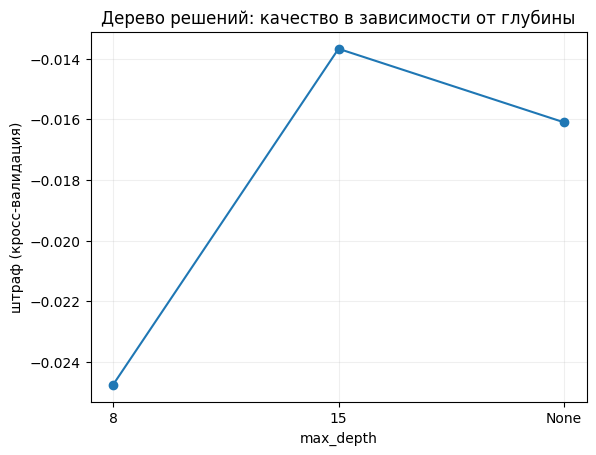

In [20]:
print(f'Используется модель со значением \'max_depth\' = {grid_tree.best_params_.get('baggingclassifier__estimator__max_depth')}')
model_tree = grid_tree.best_estimator_
y_pred = model_tree.predict(X_test)

print(f'\nПолученное значение ошибки на датасете тестирования: {accuracy_score(y_test, y_pred):.3f}')
print('Полученные характеристики:\n')
print(classification_report(y_test, y_pred, digits=3))

depths = [str(p['baggingclassifier__estimator__max_depth']) for p in grid_tree.cv_results_['params']]
scores = grid_tree.cv_results_['mean_test_score']

print('\nПолучаемое значение ошибки при разных значениях параметра \'max_depth\':\n')
plt.plot(range(len(depths)), scores, marker='o')
plt.xticks(range(len(depths)), depths)
plt.xlabel('max_depth')
plt.ylabel('штраф (кросс-валидация)')
plt.title('Дерево решений: качество в зависимости от глубины')
plt.grid(alpha=0.2)
plt.show()

# Сравнение

In [21]:
test_data = pd.read_csv(os.path.join(DATA_DIR, 'KDDTest+.csv'), header=None, names=COLS)
train_data_demo = pd.read_csv(os.path.join(DATA_DIR, 'KDDTrain+.csv'), header=None, names=COLS)
test_data['category'] = test_data['label'].map(ATTACK_CATEGORY)
train_data_demo['category'] = train_data_demo['label'].map(ATTACK_CATEGORY)
assert test_data['category'].notna().all()

new_attacks = sorted(set(test_data['label']) - set(data['label']))
print(f'Всего типов меток в \'KDDTest+\': {test_data["label"].nunique()}\nНовых меток (нет в \'KDDTrain+\'): {len(new_attacks)}')
print('Список новых типов меток: ' + ', '.join(new_attacks))
print('\nСтатистика категорий в \'KDDTrain+\':')
print(train_data_demo['category'].value_counts().to_string())
print('\nСтатистика категорий в \'KDDTest+\':')
print(test_data['category'].value_counts().to_string())

print('\nРаспределение категорий в \'KDDTrain+\':')
for cat, share in train_data_demo['category'].value_counts(normalize=True).items():
  print(f'{cat}:\t{share*100 :.2f}%')
print('\nРаспределение категорий в \'KDDTest+\':')
for cat, share in test_data['category'].value_counts(normalize=True).items():
  print(f'{cat}:\t{share*100 :.2f}%')

Всего типов меток в 'KDDTest+': 38
Новых меток (нет в 'KDDTrain+'): 17
Список новых типов меток: apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, sendmail, snmpgetattack, snmpguess, sqlattack, udpstorm, worm, xlock, xsnoop, xterm

Статистика категорий в 'KDDTrain+':
category
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52

Статистика категорий в 'KDDTest+':
category
normal    9710
dos       7460
r2l       2885
probe     2421
u2r         67

Распределение категорий в 'KDDTrain+':
normal:	53.46%
dos:	36.46%
probe:	9.25%
r2l:	0.79%
u2r:	0.04%

Распределение категорий в 'KDDTest+':
normal:	43.07%
dos:	33.09%
r2l:	12.80%
probe:	10.74%
u2r:	0.30%


Запуск сравнения:

In [22]:
# Переобучаем обе модели на ВСЁМ тренировочном наборе и проверяем на KDDTest+
# WARNING: takes 0.5 minute to run
y = data['category']
X_full, y_full = X, y
X_test_real, y_test_real = (test_data.drop(columns=['label', 'difficulty', 'category']),
                            test_data['category'])

models = [
    ('Дерево решений',
     lambda: DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ('BaggingClassifier (деревья)',
     lambda: BaggingClassifier(
         estimator=DecisionTreeClassifier(random_state=2),
         n_estimators=20,
         random_state=2,
         n_jobs=-1
     )),
]
models_real = {}
for name, make_model in models:
    model = make_pipeline(preprocess, make_model())
    t0 = time.time()
    model.fit(X_full, y_full)
    acc = model.score(X_test_real, y_test_real)
    models_real[name] = model
    print(f'Время обучение модели \'{name}\': {time.time() - t0:.1f} с\nЗначение accuracy на KDDTest+: {acc:.3f}\n')

Время обучение модели 'Дерево решений': 9.6 с
Значение accuracy на KDDTest+: 0.769

Время обучение модели 'BaggingClassifier (деревья)': 21.7 с
Значение accuracy на KDDTest+: 0.758



Оценка по внутренним параметрам:

In [25]:
# Подробный отчёт для лучшей модели (дерево решений)
y_pred_real = models_real['Дерево решений'].predict(X_test_real)
print('Подробный отчёт по одиночному дереву:')
print(classification_report(y_test_real, y_pred_real, digits=3, zero_division=0))
y_pred_real = models_real['BaggingClassifier (деревья)'].predict(X_test_real)
print('\nПодробный отчёт по дереву BaggingClassifier:')
print(classification_report(y_test_real, y_pred_real, digits=3, zero_division=0))



Подробный отчёт по одиночному дереву:
              precision    recall  f1-score   support

         dos      0.954     0.828     0.886      7460
      normal      0.700     0.966     0.811      9710
       probe      0.642     0.634     0.638      2421
         r2l      0.941     0.083     0.152      2885
         u2r      0.571     0.179     0.273        67

    accuracy                          0.769     22543
   macro avg      0.762     0.538     0.552     22543
weighted avg      0.808     0.769     0.732     22543


Подробный отчёт по дереву BaggingClassifier:
              precision    recall  f1-score   support

         dos      0.958     0.808     0.877      7460
      normal      0.667     0.968     0.790      9710
       probe      0.766     0.653     0.705      2421
         r2l      0.914     0.022     0.043      2885
         u2r      0.750     0.134     0.228        67

    accuracy                          0.758     22543
   macro avg      0.811     0.517     0.528    

По сравнению можно заключить:

! добавить результаты сравнения